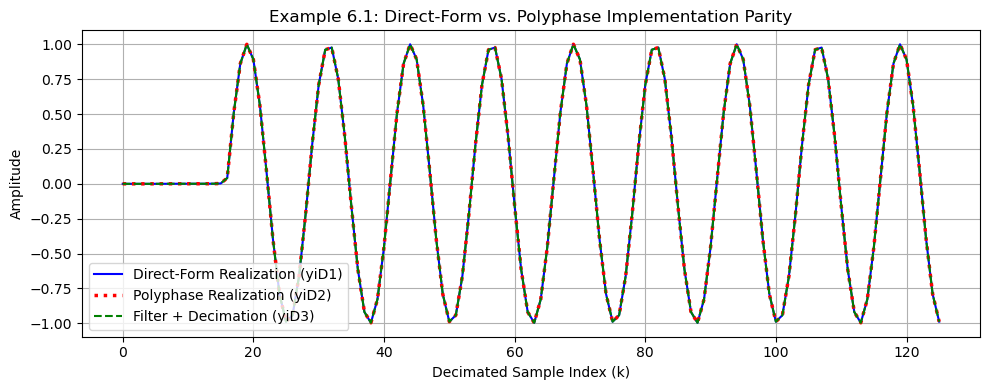

Max difference (Direct vs Polyphase)           : 3.33e-16
Max difference (Direct vs Filter+Decimation)   : 2.22e-16


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, lfilter

# ==========================================
# 1. Setup Parameters & Input Signal
# ==========================================
n_samples = 1001
ui = np.sin(2 * np.pi * 0.01 * np.arange(n_samples)) # Sine wave input signal
N = 8                                                # Number of subbands
M = 256                                              # Length of filter
w = firwin(M, cutoff=1.0 / 4.0, fs=2.0)              # Target weight vector

# ==========================================
# 2. Direct-Form Realization
# ==========================================
x_direct = np.zeros(M)
yiD1 = []
for n in range(n_samples):
    x_direct = np.concatenate(([ui[n]], x_direct[:-1])) # Update tapped-delay line
    if n % N == 0:
        yiD1.append(np.dot(w, x_direct))               # Direct-form output at decimation rate
yiD1 = np.array(yiD1)

# ==========================================
# 3. Polyphase Realization
# ==========================================
# Polyphase decomposition (reshaping into N rows x (M/N) columns using Fortran order)
W_poly = w.reshape(N, M // N, order='F')
X_poly = np.zeros((N, M // N))
xN_buf = np.zeros(N)

yiD2 = []
for n in range(n_samples):
    xN_buf = np.concatenate(([ui[n]], xN_buf[:-1]))
    if n % N == 0:
        X_poly = np.hstack((xN_buf.reshape(-1, 1), X_poly[:, :-1])) # Update polyphase buffer
        yiD2.append(np.sum(W_poly * X_poly))                         # Polyphase sum output
yiD2 = np.array(yiD2)

# ==========================================
# 4. Standard Filtering followed by Decimation
# ==========================================
yi3 = lfilter(w, [1.0], ui)
yiD3 = yi3[::N]

# ==========================================
# 5. Parity Verification & Plotting
# ==========================================
plt.figure(figsize=(10, 4))
plt.plot(yiD1, 'b', label='Direct-Form Realization (yiD1)')
plt.plot(yiD2, 'r:', label='Polyphase Realization (yiD2)', linewidth=2.5)
plt.plot(yiD3, 'g--', label='Filter + Decimation (yiD3)', linewidth=1.5)
plt.title('Example 6.1: Direct-Form vs. Polyphase Implementation Parity')
plt.xlabel('Decimated Sample Index (k)'); plt.ylabel('Amplitude')
plt.grid(True); plt.legend(); plt.tight_layout()
plt.show()

# Verification check
max_diff_12 = np.max(np.abs(yiD1 - yiD2))
max_diff_13 = np.max(np.abs(yiD1 - yiD3))
print(f"Max difference (Direct vs Polyphase)           : {max_diff_12:.2e}")
print(f"Max difference (Direct vs Filter+Decimation)   : {max_diff_13:.2e}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import remez, lfilter

# ==========================================
# 1. Helper Functions
# ==========================================
def opt_filter(filtorder: int, N: int):
    """Optimal prototype lowpass FIR filter design."""
    stopedge = 1.0 / N
    passedge = 1.0 / (4 * N)
    tol = 1e-6
    step = 0.1 * passedge
    way = -1
    pcost = 10.0
    flag = False

    while not flag:
        p = remez(filtorder + 1, [0, passedge, stopedge, 1.0], [1, 0], weight=[5, 1], fs=2.0)
        P = np.fft.fft(p, 4096)
        OptRange = int(np.floor(2048 / N))
        phi = np.zeros(OptRange)
        for k in range(1, OptRange + 1):
            phi[k - 1] = np.abs(P[OptRange - k + 1])**2 + np.abs(P[k - 1])**2
        tcost = np.max(np.abs(phi - 1.0))
        if tcost > pcost:
            step /= 2.0
            way = -way
        if np.abs(pcost - tcost) < tol:
            flag = True
        pcost = tcost
        passedge += way * step
    return p, passedge

def make_bank(p: np.ndarray, N: int):
    """Cosine-modulated analysis filter bank."""
    L = len(p)
    H = np.zeros((N, L))
    n = np.arange(L)
    for i in range(N):
        H[i, :] = 2 * p * np.cos((np.pi / N) * (i + 0.5) * (n - (L - 1) / 2.0) + ((-1)**i) * (np.pi / 4.0))
    return H

# ==========================================
# 2. Parameters & Signal Generation (6P4)
# ==========================================
M_taps = 1024                         # Adaptive filter length
N_sub = 4                             # Number of subbands (N = 4)
L_sub = 8 * N_sub                     # Filter bank length (L = 32)

# Generate AR(2) colored process excitation
np.random.seed(42)
wn = np.random.randn(80000)
a = np.array([1.0, -0.1, -0.8])
un = lfilter([1.0], a, wn)
un /= np.std(un)                      # Normalize to unit variance

# ==========================================
# 3. Filter Bank & Frequency Response Computation
# ==========================================
hopt, _ = opt_filter(L_sub - 1, N_sub)
H_bank = np.sqrt(N_sub) * make_bank(hopt, N_sub)

DFTpoint = 4096
w_freq = np.linspace(0, np.pi, DFTpoint // 2 + 1)

# Input signal power spectrum S_uu(e^{j\omega})
A_resp = np.fft.fft(a, DFTpoint)[:DFTpoint // 2 + 1]
HzSig = 1.0 / (np.abs(A_resp)**2)
HzSig /= np.var(un)

# Subband filter magnitude responses |H_i(e^{j\omega})|^2
Hz_mag = np.zeros((N_sub, DFTpoint // 2 + 1))
for i in range(N_sub):
    H_fft = np.fft.fft(H_bank[i, :], DFTpoint)[:DFTpoint // 2 + 1]
    Hz_mag[i, :] = np.abs(H_fft)**2

# Compute equivalent decorrelation filter responses
weight = np.zeros(N_sub)
Hw = np.zeros((N_sub, DFTpoint // 2 + 1))

for i in range(N_sub):
    un_i = lfilter(H_bank[i, :], [1.0], un)
    weight[i] = np.var(un_i) * M_taps
    Hw[i, :] = Hz_mag[i, :] / weight[i]

HwSum = np.sum(Hw, axis=0)
HzSigNor = HzSig * HwSum

# Compute Spectral Dynamic Range (SDR)
SDR_in = 10 * np.log10(np.max(HzSig)) - 10 * np.log10(np.min(HzSig))
SDR_out = 10 * np.log10(np.max(HzSigNor)) - 10 * np.log10(np.min(HzSigNor))

# ==========================================
# 4. Plotting Results
# ==========================================
plt.figure(figsize=(10, 8))

# Subplot 1: Input AR(2) Spectrum
plt.subplot(3, 1, 1)
plt.plot(w_freq / np.pi, 10 * np.log10(HzSig + 1e-12))
plt.title(f'Example 6.4: Input AR(2) Power Spectrum (Initial SDR = {SDR_in:.2f} dB)')
plt.ylabel('Power (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True)

# Subplot 2: Decorrelation Filter Responses
plt.subplot(3, 1, 2)
plt.plot(w_freq / np.pi, 10 * np.log10(HwSum + 1e-12), 'k', linewidth=2.0, label='Combined Decorrelation Response')
for i in range(N_sub):
    plt.plot(w_freq / np.pi, 10 * np.log10(Hw[i, :] + 1e-12), '-.', label=f'Subband #{i+1}')
plt.title('Decorrelation Filter Response H_w(z)')
plt.ylabel('Gain (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True); plt.legend(loc='lower right')

# Subplot 3: Equalized / Flattened Spectrum
plt.subplot(3, 1, 3)
plt.plot(w_freq / np.pi, 10 * np.log10(HzSigNor + 1e-12), 'r')
plt.title(f'Equalized Spectrum (Flattened SDR = {SDR_out:.2f} dB)')
plt.xlabel(r'Frequency, $\omega (\pi)$'); plt.ylabel('Power (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True)

plt.tight_layout()
plt.show()

print(f"--- Example 6.4 Results ---")
print(f"Input Spectral Dynamic Range (SDR)     : {SDR_in:.4f} dB")
print(f"Equalized Spectral Dynamic Range (SDR) : {SDR_out:.4f} dB")